# 4장. SECOM 데이터 분석 및 전처리

「AI로 만드는 제조공정 품질관리 따라하기」 4장 실습 Notebook입니다.
Google Colab에서 위에서부터 차례로 실행하면 됩니다.

In [1]:
# 실행 환경 준비: Colab이면 예제 저장소를 내려받고 실습 폴더로 이동합니다.
import os
import sys
from pathlib import Path

if "google.colab" in sys.modules and not Path("src").exists():
    !git clone -q https://github.com/ady95/manufacturing-ai-tutorial.git
    %cd manufacturing-ai-tutorial/01-yield-risk

ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))
Path("results").mkdir(exist_ok=True)

In [2]:
import json
import platform

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn

from src.secom_utils import SEED, load_secom, dev_test_split

print("Python", platform.python_version(), "| pandas", pd.__version__, "| scikit-learn", sklearn.__version__)

Python 3.12.9 | pandas 3.1.1 | scikit-learn 1.9.1


## 4-1. 데이터 취득과 탐색

In [3]:
X, y, ts = load_secom()
print("특성 행렬:", X.shape)
print("라벨:", y.shape, "| 시각:", ts.min(), "~", ts.max())
X.iloc[:5, :8]

특성 행렬: (1567, 590)
라벨: (1567,) | 시각: 2008-07-19 11:55:00 ~ 2008-10-17 06:07:00


,f000,f001,f002,f003,f004,f005,f006,f007
0,3030.93,2564.00,2187.7333,1411.1265,1.3602,100.0,97.6133,0.1242
1,3095.78,2465.14,2230.4222,1463.6606,0.8294,100.0,102.3433,0.1247
2,2932.61,2559.94,2186.4111,1698.0172,1.5102,100.0,95.4878,0.1241
3,2988.72,2479.90,2199.0333,909.7926,1.3204,100.0,104.2367,0.1217
4,3032.24,2502.87,2233.3667,1326.5200,1.5334,100.0,100.3967,0.1235


In [4]:
counts = y.value_counts().sort_index()
print(counts.rename({0: "Pass(양품)", 1: "Fail(불량)"}))
print(f"불량률: {y.mean():.4f}")
print(f"모두 양품이라고 답하는 모델의 정확도: {1 - y.mean():.4f}")

fail
Pass(양품)    1463
Fail(불량)     104
Name: count, dtype: int64
불량률: 0.0664
모두 양품이라고 답하는 모델의 정확도: 0.9336


           n  fails  fail_rate
ts                            
2008-07   63     14   0.222222
2008-08  555     51   0.091892
2008-09  590     17   0.028814
2008-10  359     22   0.061281


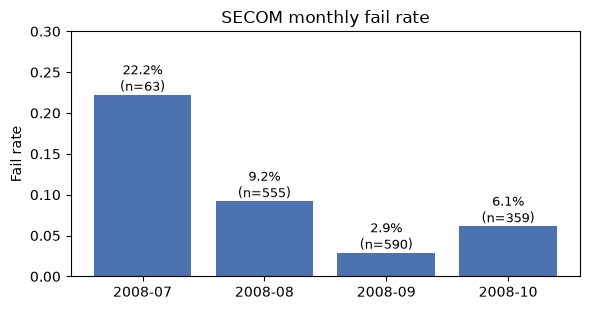

In [5]:
monthly = (
    pd.DataFrame({"ts": ts, "fail": y})
    .set_index("ts")
    .resample("MS")["fail"]
    .agg(["count", "sum", "mean"])
    .rename(columns={"count": "n", "sum": "fails", "mean": "fail_rate"})
)
monthly.index = monthly.index.strftime("%Y-%m")
print(monthly)

fig, ax = plt.subplots(figsize=(6, 3.2))
ax.bar(monthly.index, monthly["fail_rate"], color="#4C72B0")
for i, (rate, n) in enumerate(zip(monthly["fail_rate"], monthly["n"])):
    ax.text(i, rate + 0.005, f"{rate:.1%}\n(n={n})", ha="center", fontsize=9)
ax.set_ylabel("Fail rate")
ax.set_title("SECOM monthly fail rate")
ax.set_ylim(0, monthly["fail_rate"].max() * 1.35)
fig.tight_layout()
fig.savefig("results/04_monthly_fail_rate.png", dpi=150)
plt.show()

## 4-2. 클래스 분포, 결측치, 특성 품질 확인

전체 셀 결측 비율: 0.0454
결측이 하나라도 있는 행: 1567 / 1567
결측 비율 >    0: 538개 특성
결측 비율 > 0.05:  52개 특성
결측 비율 >  0.2:  32개 특성
결측 비율 >  0.5:  28개 특성
결측 비율 >  0.8:   8개 특성


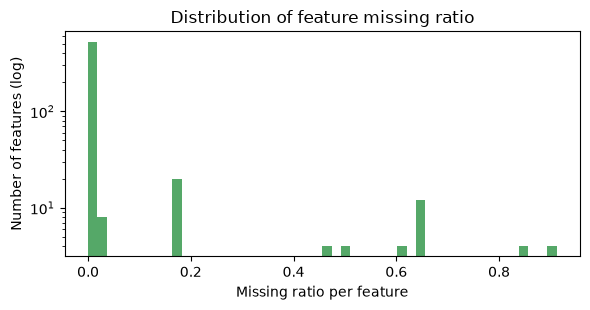

In [6]:
miss = X.isna().mean()
print(f"전체 셀 결측 비율: {X.isna().to_numpy().mean():.4f}")
print(f"결측이 하나라도 있는 행: {X.isna().any(axis=1).sum()} / {len(X)}")
for t in [0, 0.05, 0.2, 0.5, 0.8]:
    print(f"결측 비율 > {t:>4}: {(miss > t).sum():3d}개 특성")

fig, ax = plt.subplots(figsize=(6, 3.2))
ax.hist(miss, bins=50, color="#55A868")
ax.set_yscale("log")
ax.set_xlabel("Missing ratio per feature")
ax.set_ylabel("Number of features (log)")
ax.set_title("Distribution of feature missing ratio")
fig.tight_layout()
fig.savefig("results/04_missing_ratio_hist.png", dpi=150)
plt.show()

In [7]:
nunique = X.nunique(dropna=True)
constant = nunique[nunique <= 1].index
dup_mask = X.T.duplicated()
dup_nonconst = X.loc[:, dup_mask & (nunique > 1)].columns
print("값이 하나뿐인(상수) 특성:", len(constant))
print("다른 열과 완전히 같은 특성:", int(dup_mask.sum()), "(그중 상수가 아닌 것:", len(dup_nonconst), ")")

값이 하나뿐인(상수) 특성: 116
다른 열과 완전히 같은 특성: 104 (그중 상수가 아닌 것: 0 )


In [8]:
# 불량/양품 간 결측 비율 차이: 결측 자체가 정보일 수 있는지 확인합니다.
miss_fail = X[y == 1].isna().mean()
miss_pass = X[y == 0].isna().mean()
diff = (miss_fail - miss_pass).sort_values()
print("불량에서 결측이 더 많은 특성 상위 5개:")
print(diff.tail(5).round(3))
print("양품에서 결측이 더 많은 특성 상위 5개:")
print(diff.head(5).round(3))

불량에서 결측이 더 많은 특성 상위 5개:
f245    0.066
f246    0.066
f382    0.066
f383    0.066
f384    0.066
dtype: float64
양품에서 결측이 더 많은 특성 상위 5개:
f346   -0.172
f345   -0.172
f072   -0.172
f073   -0.172
f247   -0.149
dtype: float64


## 4-3. 데이터 누수 방지와 검증 구성

In [9]:
(X_dev, y_dev, ts_dev), (X_test, y_test, ts_test) = dev_test_split(X, y, ts, test_size=0.2)
split_info = pd.DataFrame({
    "n": [len(y_dev), len(y_test)],
    "fails": [int(y_dev.sum()), int(y_test.sum())],
    "fail_rate": [y_dev.mean(), y_test.mean()],
    "start": [ts_dev.min(), ts_test.min()],
    "end": [ts_dev.max(), ts_test.max()],
}, index=["dev", "test"])
split_info

,n,fails,fail_rate,start,end
dev,1253,87,0.069433,2008-07-19 11:55:00,2008-10-02 19:25:00
test,314,17,0.054140,2008-10-02 20:54:00,2008-10-17 06:07:00


### 누수 실험: 특성 선택을 분리 전에 하면?

같은 모델(특성 40개 선택 + Logistic Regression)을 두 방식으로 평가합니다.
- (A) 잘못된 방식: 개발 데이터 전체로 특성을 먼저 고른 뒤 교차검증
- (B) 올바른 방식: 특성 선택을 파이프라인에 넣어 학습 폴드에서만 적합

In [10]:
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import Pipeline

from src.secom_utils import make_preprocessor


def lr_model():
    return LogisticRegression(C=0.1, class_weight="balanced", max_iter=5000)


cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
K = 40

# (A) 누수: 전처리와 특성 선택을 개발 데이터 전체에 먼저 적합
prep_all = make_preprocessor(scale=True).fit(X_dev)
Z_all = prep_all.transform(X_dev)
selector_all = SelectKBest(f_classif, k=K).fit(Z_all, y_dev)
Z_sel = selector_all.transform(Z_all)
leaky = []
for tr, te in cv.split(Z_sel, y_dev):
    m = lr_model().fit(Z_sel[tr], y_dev.iloc[tr])
    leaky.append(average_precision_score(y_dev.iloc[te], m.predict_proba(Z_sel[te])[:, 1]))

# (B) 올바른 방식: 모든 전처리를 파이프라인 안에서 학습 폴드에만 적합
clean = []
for tr, te in cv.split(X_dev, y_dev):
    pipe = Pipeline([
        ("prep", make_preprocessor(scale=True)),
        ("select", SelectKBest(f_classif, k=K)),
        ("clf", lr_model()),
    ]).fit(X_dev.iloc[tr], y_dev.iloc[tr])
    clean.append(average_precision_score(y_dev.iloc[te], pipe.predict_proba(X_dev.iloc[te])[:, 1]))

print(f"(A) 분리 전 특성 선택  PR-AUC: {np.mean(leaky):.3f} ± {np.std(leaky):.3f}")
print(f"(B) 파이프라인 안 선택 PR-AUC: {np.mean(clean):.3f} ± {np.std(clean):.3f}")
print(f"참고: 개발 데이터 불량률(무작위 모델의 기대 PR-AUC): {y_dev.mean():.3f}")

(A) 분리 전 특성 선택  PR-AUC: 0.236 ± 0.050
(B) 파이프라인 안 선택 PR-AUC: 0.186 ± 0.033
참고: 개발 데이터 불량률(무작위 모델의 기대 PR-AUC): 0.069


In [11]:
result = {
    "env": {"python": platform.python_version(), "pandas": pd.__version__, "sklearn": sklearn.__version__},
    "shape": list(X.shape),
    "fails": int(y.sum()),
    "fail_rate": round(float(y.mean()), 4),
    "all_pass_accuracy": round(float(1 - y.mean()), 4),
    "ts_range": [str(ts.min()), str(ts.max())],
    "monthly": monthly.reset_index().rename(columns={"ts": "month"}).round(4).to_dict(orient="records"),
    "cell_missing_ratio": round(float(X.isna().to_numpy().mean()), 4),
    "features_missing_gt": {str(t): int((miss > t).sum()) for t in [0, 0.05, 0.2, 0.5, 0.8]},
    "constant_features": int(len(constant)),
    "duplicate_features": int(dup_mask.sum()),
    "duplicate_nonconstant": int(len(dup_nonconst)),
    "split": {k: {"n": int(v["n"]), "fails": int(v["fails"]), "fail_rate": round(float(v["fail_rate"]), 4),
                  "start": str(v["start"]), "end": str(v["end"])} for k, v in split_info.iterrows()},
    "leakage_demo": {"k": K, "leaky_mean": round(float(np.mean(leaky)), 3), "leaky_std": round(float(np.std(leaky)), 3),
                     "clean_mean": round(float(np.mean(clean)), 3), "clean_std": round(float(np.std(clean)), 3)},
}
Path("results/04_eda.json").write_text(json.dumps(result, ensure_ascii=False, indent=2), encoding="utf-8")
print(json.dumps(result["leakage_demo"], ensure_ascii=False))

{"k": 40, "leaky_mean": 0.236, "leaky_std": 0.05, "clean_mean": 0.186, "clean_std": 0.033}
